# Visualisasi Sebaran Resistivitas

# 1. Import Library dan Package

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import pygmt
INPUT_DIR = r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\03. EXTRACT DEPTH"
OUTPUT_GMT = r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv"
csv_files = glob.glob(os.path.join(INPUT_DIR, "*_EXTRACT with TOLERANCE DEPTH*.csv"))
df_master = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
os.makedirs(os.path.dirname(OUTPUT_GMT), exist_ok=True)
df_master.to_csv(OUTPUT_GMT, index=False)
print(f"File siap untuk PyGMT: {OUTPUT_GMT}")

File siap untuk PyGMT: C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv


In [2]:
import sys
print(sys.executable)

C:\Users\axioo\anaconda3\envs\mtpy\python.exe


# 2. Pemrosesan Data dan Plotting Peta PyGMT


[SUKSES] Peta disimpan di: GMT_PSEUDOSECTION HORIZONTAL MAP.png


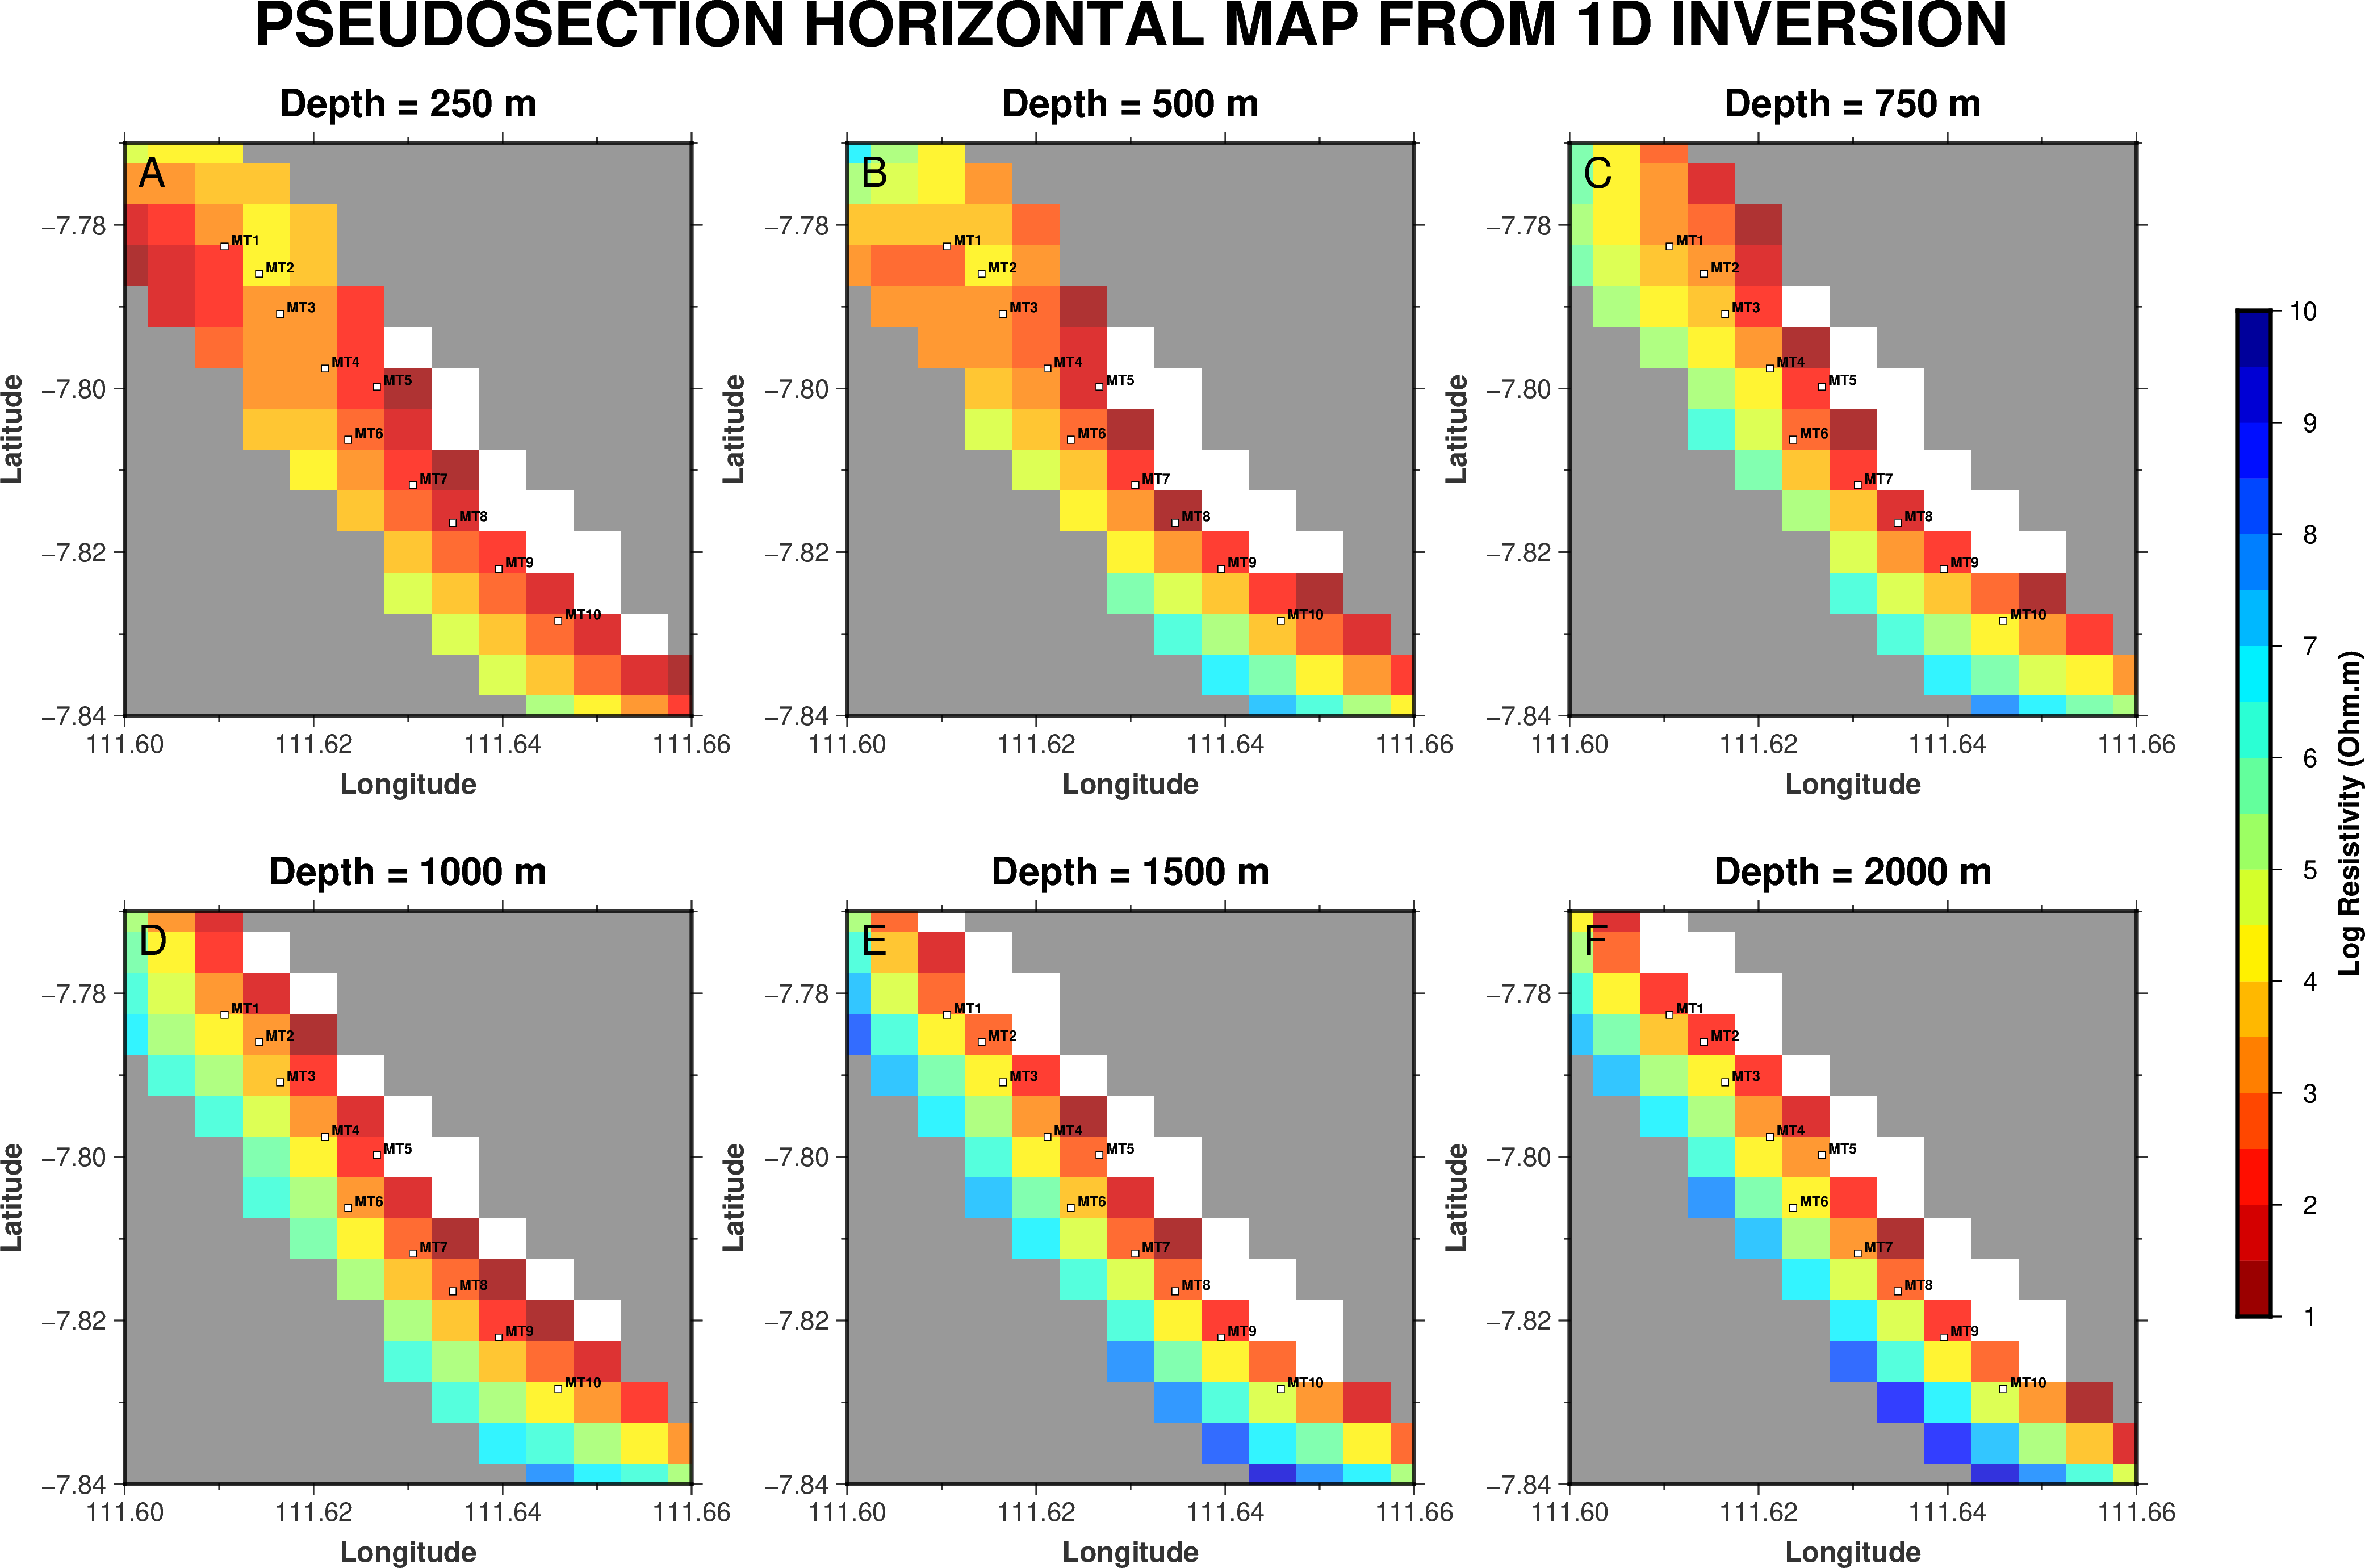

In [3]:
FILE_INPUT = r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv"
OUTPUT_DIR = r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\04. PLOT HORIZONTAL"
NAMA_FILE_OUTPUT = "GMT_PSEUDOSECTION HORIZONTAL MAP.png"
DEPTHS_TO_PLOT = [250, 500, 750, 1000, 1500, 2000]
df = pd.read_csv(FILE_INPUT)
margin = 0.01  # dikecilkan dari 0.05 supaya peta zoom/fit ke lintasan stasiun
res_grid = 0.01
REGION = [
    np.floor((df['Longitude'].min() - margin) / res_grid) * res_grid,
    np.ceil((df['Longitude'].max() + margin) / res_grid) * res_grid,
    np.floor((df['Latitude'].min() - margin) / res_grid) * res_grid,
    np.ceil((df['Latitude'].max() + margin) / res_grid) * res_grid
]
os.chdir(OUTPUT_DIR)
fig = pygmt.Figure()
pygmt.config(
    MAP_HEADING_OFFSET="0.5c",
    MAP_TITLE_OFFSET="0.4c",
    FONT_HEADING="26p,Helvetica-Bold,black",
    FONT_TITLE="16p,Helvetica-Bold,black",
    FONT_LABEL="12p,Helvetica-Bold,black",
    MAP_LABEL_OFFSET="0.3c"
)
pygmt.makecpt(cmap="jet", series="1/10/0.5", reverse=True, output="GMT_RESISTIVITY.cpt")
with fig.subplot(nrows=2, ncols=3, figsize=("30c", "20c"), margins=["0.5c", "0.8c"], title="PSEUDOSECTION HORIZONTAL MAP FROM 1D INVERSION", frame=["WSne", "xaf+lLongitude", "yaf+lLatitude"], autolabel="A+jTL+o0.2c/0.2c"):
    for i, depth in enumerate(DEPTHS_TO_PLOT):
        with fig.set_panel(panel=i):
            subset_df = df[np.isclose(df['Depth'], depth, atol=2.0)]
            if len(subset_df) > 2:
                block = pygmt.blockmedian(data=subset_df[["Longitude", "Latitude", "Log Resistivity"]], region=REGION, spacing="0.005")
                grid = pygmt.surface(data=block, region=REGION, spacing="0.005")
                # --- FIX: batasi grid hanya di sekitar garis lintasan stasiun ---
                # Pakai PCA dari koordinat SEMUA stasiun unik (tidak bergantung urutan baris di df,
                # yang bisa keliru kalau df hasil concat file per-stasiun dengan urutan alfabetis)
                station_coords = df[['Station', 'Longitude', 'Latitude']].drop_duplicates(subset='Station')
                pts = station_coords[['Longitude', 'Latitude']].to_numpy()
                centroid = pts.mean(axis=0)
                _, _, vh = np.linalg.svd(pts - centroid)
                direction = vh[0]  # arah vektor utama garis lintasan
                perp_dir = np.array([-direction[1], direction[0]])  # arah tegak lurus garis
                proj_stations = (pts - centroid) @ direction
                t_min, t_max = proj_stations.min(), proj_stations.max()

                gx, gy = grid.x.values, grid.y.values  # ganti ke grid.lon/grid.lat kalau nama koordinatnya beda
                lon2d, lat2d = np.meshgrid(gx, gy)
                grid_pts = np.column_stack([lon2d.ravel(), lat2d.ravel()]) - centroid
                proj_grid = (grid_pts @ direction).reshape(lon2d.shape)
                perp_grid = np.abs(grid_pts @ perp_dir).reshape(lon2d.shape)

                BUFFER_PERP_DEG = 0.01    # jarak tegak lurus dari garis yang masih ditampilkan (~1 km, sesuaikan)
                BUFFER_ALONG_DEG = 0.02   # margin ekstra di ujung-ujung garis, dalam derajat (~2 km, sesuaikan)
                mask = (perp_grid <= BUFFER_PERP_DEG) & (proj_grid >= t_min - BUFFER_ALONG_DEG) & (proj_grid <= t_max + BUFFER_ALONG_DEG)
                grid = grid.where(mask)
                fig.grdimage(grid=grid, cmap="GMT_RESISTIVITY.cpt", transparency=20)
            fig.coast(shorelines="0.5p,black", region=REGION, resolution='i')
            fig.basemap(region=REGION, frame=[f"+tDepth = {int(depth)} m"])
            if not subset_df.empty:
                fig.plot(x=subset_df['Longitude'], y=subset_df['Latitude'], style="s0.15c", fill="white", pen="black")
                fig.text(x=subset_df['Longitude'], y=subset_df['Latitude'], text=subset_df['Station'], font="6p,Helvetica-Bold,black", offset="0.1c/0.1c", justify="ML")
fig.colorbar(cmap="GMT_RESISTIVITY.cpt", position="JMR+o1.5c/0c+w15c/0.5c", frame=["a1", "x+lLog Resistivity (Ohm.m)"])
fig.savefig(NAMA_FILE_OUTPUT, crop="+m0.5c")
print(f"\n[SUKSES] Peta disimpan di: {NAMA_FILE_OUTPUT}")
fig.show()

In [4]:
print(df.columns.tolist())
print(df.head())

['Station', 'Depth', 'Resistivity Mean', 'Log Resistivity', 'Latitude', 'Longitude', 'Elevation']
  Station   Depth  Resistivity Mean  Log Resistivity  Latitude   Longitude  \
0    MT10   250.0           206.414            2.315 -7.828389  111.645889   
1    MT10   500.0          1324.610            3.122 -7.828389  111.645889   
2    MT10   750.0          3341.893            3.524 -7.828389  111.645889   
3    MT10  1000.0          5186.290            3.715 -7.828389  111.645889   
4    MT10  1250.0          6497.144            3.813 -7.828389  111.645889   

   Elevation  
0    845.186  
1    845.186  
2    845.186  
3    845.186  
4    845.186  


In [5]:
print(df.dtypes)
print(df['Longitude'].unique()[:10])

Station                 str
Depth               float64
Resistivity Mean    float64
Log Resistivity     float64
Latitude            float64
Longitude           float64
Elevation           float64
dtype: object
[111.645889 111.610583 111.614222 111.616472 111.621194 111.626694
 111.623667 111.6305   111.634722 111.639583]


In [6]:
with open(FILE_INPUT, encoding='utf-8', errors='ignore') as f:
    for i, line in enumerate(f):
        print(line)
        if i > 3: break

Station,Depth,Resistivity Mean,Log Resistivity,Latitude,Longitude,Elevation

MT10,250.0,206.414,2.315,-7.828389,111.645889,845.186

MT10,500.0,1324.61,3.122,-7.828389,111.645889,845.186

MT10,750.0,3341.893,3.524,-7.828389,111.645889,845.186

MT10,1000.0,5186.29,3.715,-7.828389,111.645889,845.186



In [7]:
with open(r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\03. EXTRACT DEPTH\MT6_EXTRACT with TOLERANCE DEPTH.csv", encoding='utf-8') as f:
    for i, line in enumerate(f):
        print(line)
        if i > 3: break

Station,Depth,Resistivity Mean,Log Resistivity,Latitude,Longitude,Elevation

MT6,250.0,1474.581,3.169,-7.80625,111.623667,749.171

MT6,500.0,2348.754,3.371,-7.80625,111.623667,749.171

MT6,750.0,4114.27,3.614,-7.80625,111.623667,749.171

MT6,1000.0,7416.368,3.87,-7.80625,111.623667,749.171

